# Company Default Prediction

**Goal:** predict whether a company will default, using its financial data.

**Definition used:** a company is a *default* when its net worth next year is zero or below.

**How this notebook is organised:** load data, clean, prepare the target, compare 3 models, choose the final model and threshold, test it once on unseen data, and save it.

Run the cells from top to bottom.

In [4]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.impute import KNNImputer
from sklearn.metrics import (classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             roc_auc_score, average_precision_score, precision_recall_curve)
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_predict

## 1. Load the data and clean the column names

In [5]:
company = pd.read_csv("Company data.csv")
company.columns = (
    company.columns.str.replace(" ", "_", regex=False)
    .str.replace("(", "", regex=False)
    .str.replace(")", "", regex=False)
    .str.replace("%", "perc", regex=False)
    .str.replace("/", "_to_", regex=False)
)
print("Rows and columns:", company.shape)
company.head()

Rows and columns: (3541, 52)


,Num,Networth_Next_Year,Total_assets,Net_worth,Total_income,Change_in_stock,Total_expenses,Profit_after_tax,PBDITA,PBT,...,Debtors_turnover,Finished_goods_turnover,WIP_turnover,Raw_material_turnover,Shares_outstanding,Equity_face_value,EPS,Adjusted_EPS,Total_liabilities,PE_on_BSE
0,1,8890.6,17512.3,7093.2,24965.2,235.8,23657.8,1543.2,2860.2,2417.2,...,3.85,200.55,21.78,7.71,42381675.0,10.0,35.52,7.10,17512.3,27.31
1,2,394.3,941.0,351.5,1527.4,42.7,1454.9,115.2,283.0,188.4,...,5.70,14.21,7.49,11.46,11550000.0,10.0,9.97,9.97,941.0,8.17
2,3,92.2,232.8,100.6,477.3,-5.2,478.7,-6.6,5.8,-6.6,...,5.07,9.24,0.23,NaN,8149090.0,10.0,-0.50,-0.50,232.8,-5.76
3,4,2.7,2.7,2.7,NaN,NaN,NaN,NaN,NaN,NaN,...,0.00,NaN,NaN,0.00,52404.0,10.0,0.00,0.00,2.7,NaN
4,5,109.0,478.5,107.6,1580.5,-17.0,1558.0,5.5,31.0,6.3,...,9.46,12.68,7.90,17.03,619635.0,10.0,7.91,7.91,478.5,NaN


## 2. Create the target

A company is marked as default (1) when `Networth_Next_Year` is 0 or below.
Then we remove `Networth_Next_Year`, because it defines the answer. Keeping it would be cheating.

In [6]:
company["default"] = np.where(company["Networth_Next_Year"] <= 0, 1, 0)
print(company["default"].value_counts())
print("Default rate:", round(company["default"].mean() * 100, 1), "%")

default
0    3298
1     243
Name: count, dtype: int64
Default rate: 6.9 %


**Important:** only a small share of companies default, so the data is *imbalanced*.
A model that always says "no default" would already look about 93% accurate. That is why we will use recall, precision, PR-AUC and ROC-AUC instead of accuracy.

## 3. Missing values

Some columns have many missing values. We drop the ones with too many, and fill the rest inside the model pipeline (KNN imputer), so no information from the test data leaks into training.

In [7]:
missing = (company.isna().mean() * 100).sort_values(ascending=False)
missing.head(12).round(1)

Deposits_accepted_by_commercial_banks    100.0
PE_on_BSE                                 62.0
Investments                               40.5
Other_income                              36.6
Contingent_liabilities                    33.5
Deferred_tax_liability                    32.2
Income_from_financial_services            26.4
Finished_goods_turnover                   20.9
Shares_outstanding                        19.5
Equity_face_value                         19.5
WIP_turnover                              18.1
Change_in_stock                           12.9
dtype: float64

In [8]:
drop_cols = [
    "Deposits_accepted_by_commercial_banks", "PE_on_BSE", "Investments",
    "Other_income", "Contingent_liabilities", "Deferred_tax_liability",
    "Income_from_financial_services",
    "Num",   # company id, not a financial feature
]
y = company["default"]
X = company.drop(columns=["default", "Networth_Next_Year"] + drop_cols)
print("Features left:", X.shape[1])

Features left: 43


## 4. Split into train and test

The test set is kept aside and used **only once**, at the very end.
`stratify=y` keeps the same default rate in both parts.

In [9]:
X_tr, X_te, y_tr, y_te = train_test_split(
    X, y, test_size=0.25, stratify=y, random_state=2
)
print("Train:", X_tr.shape, "| Test:", X_te.shape)
print("Defaults in test set:", int(y_te.sum()))

Train: (2655, 43) | Test: (886, 43)
Defaults in test set: 61


## 5. Compare three models (5-fold cross-validation on the training data)

| Model | Idea |
|---|---|
| 1 | Random Forest + SMOTE (creates extra default examples) |
| 2 | Random Forest + class weights (gives defaults more importance) |
| 3 | Gradient boosting + class weights |

**PR-AUC** is the main score here, because defaults are rare. Higher is better.

In [10]:
models = {
    "1. RF + SMOTE": ImbPipeline([
        ("imp", KNNImputer(n_neighbors=11)),
        ("smote", SMOTE(random_state=33)),
        ("m", RandomForestClassifier(n_estimators=300, random_state=2, n_jobs=-1)),
    ]),
    "2. RF + class_weight": Pipeline([
        ("imp", KNNImputer(n_neighbors=11)),
        ("m", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                     min_samples_leaf=3, random_state=2, n_jobs=-1)),
    ]),
    "3. Gradient boosting + class_weight": HistGradientBoostingClassifier(
        class_weight="balanced", max_depth=4, learning_rate=0.05, random_state=2),
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=2)
rows = []
for name, m in models.items():
    p = cross_val_predict(m, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
    prec, rec, thr = precision_recall_curve(y_tr, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-9)
    b = np.argmax(f1[:-1])
    rows.append({"model": name,
                 "ROC-AUC": round(roc_auc_score(y_tr, p), 3),
                 "PR-AUC": round(average_precision_score(y_tr, p), 3),
                 "best threshold": round(thr[b], 2),
                 "precision": round(prec[b], 2),
                 "recall": round(rec[b], 2)})
pd.DataFrame(rows)

,model,ROC-AUC,PR-AUC,best threshold,precision,recall
0,1. RF + SMOTE,0.930,0.559,0.56,0.59,0.65
1,2. RF + class_weight,0.933,0.621,0.45,0.67,0.67
2,3. Gradient boosting + class_weight,0.927,0.611,0.76,0.62,0.63


**Choice:** Random Forest with class weights (model 2) has the best PR-AUC and the best precision and recall together, and it is simpler than SMOTE.

## 6. Final model and decision threshold

The model gives a score between 0 and 1. A company is *flagged* when its score reaches the threshold.
The default threshold of 0.5 is not best for rare defaults, so we pick the threshold with the best F1 score using cross-validation on the **training** data only.

In [11]:
final_model = Pipeline([
    ("imputer", KNNImputer(n_neighbors=11)),
    ("rf", RandomForestClassifier(n_estimators=300, class_weight="balanced_subsample",
                                  min_samples_leaf=3, random_state=2, n_jobs=-1)),
])

p_cv = cross_val_predict(final_model, X_tr, y_tr, cv=cv, method="predict_proba")[:, 1]
prec, rec, thr = precision_recall_curve(y_tr, p_cv)
f1 = 2 * prec * rec / (prec + rec + 1e-9)
THRESHOLD = round(float(thr[np.argmax(f1[:-1])]), 2)
print("Chosen threshold:", THRESHOLD)

Chosen threshold: 0.45


## 7. Final check on the test set (look at this once)

In [12]:
final_model.fit(X_tr, y_tr)
proba = final_model.predict_proba(X_te)[:, 1]
pred = (proba >= THRESHOLD).astype(int)

print(classification_report(y_te, pred))
print("ROC-AUC:", round(roc_auc_score(y_te, proba), 3))
print("PR-AUC:", round(average_precision_score(y_te, proba), 3))

              precision    recall  f1-score   support

           0       0.97      0.98      0.97       825
           1       0.66      0.61      0.63        61

    accuracy                           0.95       886
   macro avg       0.82      0.79      0.80       886
weighted avg       0.95      0.95      0.95       886

ROC-AUC: 0.941
PR-AUC: 0.623


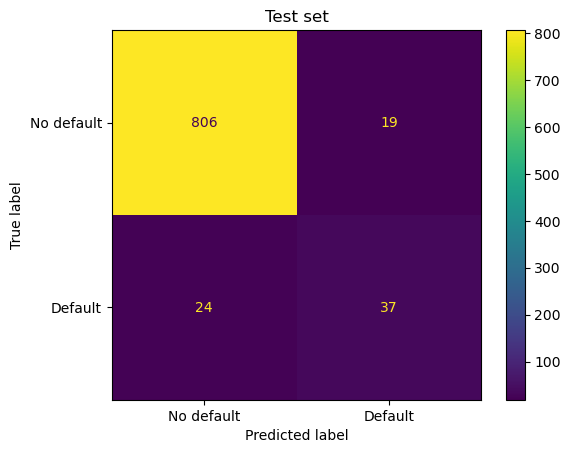

In [13]:
ConfusionMatrixDisplay(confusion_matrix(y_te, pred),
                       display_labels=["No default", "Default"]).plot()
plt.title("Test set")
plt.show()

**How to read this:** recall for the default class is the share of real defaults the model catches. Precision is how often a flagged company is a real default.
The model supports an analyst, it does not replace one.

## 8. Which features matter most?

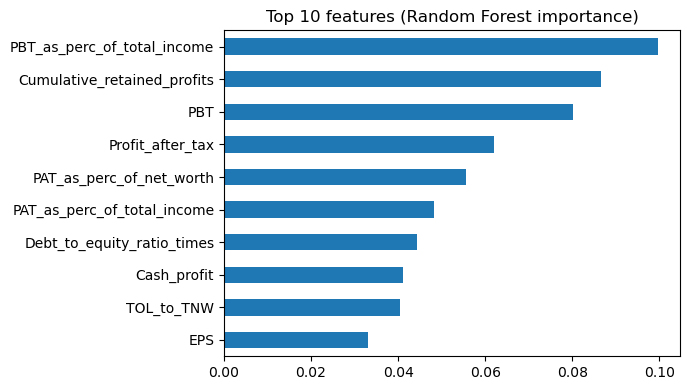

In [14]:
imp = pd.Series(final_model.named_steps["rf"].feature_importances_, index=X.columns)
imp.sort_values().tail(10).plot(kind="barh", figsize=(7, 4))
plt.title("Top 10 features (Random Forest importance)")
plt.tight_layout()
plt.show()

## 9. Save the model

In [15]:
joblib.dump({"model": final_model, "features": X.columns.tolist(), "threshold": THRESHOLD},
            "default_model.pkl")
print("Saved default_model.pkl with", X.shape[1], "features")

Saved default_model.pkl with 43 features


## Summary

- Defaults are rare, so accuracy is misleading. Recall, precision, PR-AUC and ROC-AUC are used.
- Three models were compared with cross-validation. Random Forest with class weights was chosen.
- The decision threshold was chosen on training data only. The test set was used once.
- Limits: the model finds a bit more than half of the real defaults, so it should support human review and not make decisions alone.